# 02 · Regresión: publicidad y ventas

**Pregunta de negocio 1:** ¿cuánto se vende por cada euro invertido en publicidad?

Datos: una fila por mes (24 meses, de 2024-11 a 2026-10) creada con `tabla_mensual()` de
`src/features.py`. Solo cuentan los pedidos completados.

> Requisito: haber ejecutado `python src/generar_datos.py` y `python src/limpieza.py`.

## 0. Configuración y carga

In [1]:
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.linear_model import HuberRegressor, LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import LeaveOneOut, cross_val_predict

# El notebook se ejecuta desde notebooks/: src está en ../src
RAIZ = Path.cwd().parent
sys.path.append(str(RAIZ / "src"))
from features import tabla_mensual  # noqa: E402

SEMILLA = 42
CARPETA_IMG = RAIZ / "docs" / "img"
CARPETA_IMG.mkdir(parents=True, exist_ok=True)
CARPETA_MODELOS = RAIZ / "models"
CARPETA_MODELOS.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#8a8984"
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)


def euros(valor, decimales=0):
    """12345.6 -> '12.346 €' (formato español)."""
    texto = f"{valor:,.{decimales}f}".replace(",", "X").replace(".", ",").replace("X", ".")
    return f"{texto} €"


def num(valor, decimales=2):
    """1234.567 -> '1.234,57' (número en formato español, sin unidad)."""
    return f"{valor:,.{decimales}f}".replace(",", "X").replace(".", ",").replace("X", ".")


FORMATO_EUROS = mticker.FuncFormatter(lambda valor, _pos: euros(valor))


def guardar(fig, nombre):
    """Guarda la figura en docs/img/regresion_<nombre>.png.

    metadata={"Software": None} quita la versión de matplotlib del PNG: con los mismos datos,
    el archivo es idéntico byte a byte entre ejecuciones.
    """
    fig.savefig(CARPETA_IMG / f"regresion_{nombre}.png", dpi=120, bbox_inches="tight",
                metadata={"Software": None})

In [2]:
mensual = tabla_mensual()
umbral = mensual.attrs["umbral_extremos"]
print(f"{len(mensual)} meses, de {mensual['mes'].iloc[0]} a {mensual['mes'].iloc[-1]}")
print(f"Umbral de pedido extremo = Q3 + 3·IQR = {num(umbral['q3'])} + 3 × {num(umbral['iqr'])} = {euros(umbral['umbral'], 2)}")
print(f"Pedidos extremos: {umbral['n_extremos']} de {umbral['n_pedidos']} "
      f"({num(100 * umbral['n_extremos'] / umbral['n_pedidos'], 1)} %), que suman "
      f"{num(100 * (1 - mensual['ingresos_sin_extremos'].sum() / mensual['ingresos'].sum()), 1)} % de los ingresos")
mensual.round(2)

24 meses, de 2024-11 a 2026-10
Umbral de pedido extremo = Q3 + 3·IQR = 165,84 + 3 × 121,76 = 531,12 €
Pedidos extremos: 161 de 6541 (2,5 %), que suman 18,3 % de los ingresos


,mes,mes_del_anio,temporada_alta,inversion_total,inversion_google_ads,inversion_meta_ads,inversion_email,n_pedidos,ingresos,coste_productos,margen_bruto,ingresos_sin_extremos,margen_sin_extremos,n_pedidos_extremos
0,2024-11,11,1,4805.81,3423.51,923.33,458.97,411,62425.84,36089.54,26336.30,46665.91,18633.41,7
1,2024-12,12,1,5149.78,2582.35,2184.11,383.32,372,50417.97,29762.36,20655.61,39475.91,16060.12,14
2,2025-01,1,0,4490.81,2228.52,2029.82,232.47,304,42475.15,25005.74,17469.41,33720.67,13666.75,8
3,2025-02,2,0,2909.23,1765.05,1026.49,117.69,201,27021.07,16310.12,10710.95,23066.57,9091.19,5
4,2025-03,3,0,2857.55,2146.12,538.11,173.32,232,27495.94,16662.07,10833.87,24514.19,9747.22,3
5,2025-04,4,0,2125.18,981.80,859.14,284.24,212,28589.63,17205.50,11384.13,24006.95,9648.66,7
6,2025-05,5,0,3651.81,2182.65,1342.11,127.05,318,39239.53,23612.03,15627.50,32411.59,12564.54,7
7,2025-06,6,0,3192.12,1709.02,1174.97,308.13,261,31654.56,18959.69,12694.87,28352.00,11216.85,4
8,2025-07,7,0,3506.27,1912.00,1367.38,226.89,257,33859.34,20296.77,13562.57,28876.94,11620.28,6
9,2025-08,8,0,4492.53,2533.86,1742.95,215.72,284,38823.50,22979.72,15843.78,31778.24,12879.29,10


**Lectura:** 24 meses, uno por fila. El umbral de pedido extremo es Q3 + 3·IQR = 531,12 €. Ojo: no marca solo los 2 pedidos gigantes del EDA, sino 161 pedidos (2,5 % del total) que suman el 18,3 % de los ingresos. El importe por pedido tiene una cola larga natural: un carrito con varios productos Premium ya supera ese umbral.

## 1. Regresión simple a mano: `n_pedidos ~ inversion_total`

La recta es **n_pedidos = β₀ + β₁ · inversion_total**. Por mínimos cuadrados:

- β₁ = Σ(x − x̄)(y − ȳ) / Σ(x − x̄)²
- β₀ = ȳ − β₁ · x̄

In [3]:
x = mensual["inversion_total"].to_numpy()
y = mensual["n_pedidos"].to_numpy()

# Paso 1: medias
x_media = x.mean()
y_media = y.mean()
print(f"x̄ (inversión media) = {x_media:.4f} €")
print(f"ȳ (pedidos medios)  = {y_media:.4f}")

# Paso 2: desviaciones respecto a la media
dx = x - x_media
dy = y - y_media

# Paso 3: las dos sumas
suma_productos = np.sum(dx * dy)   # Σ(x − x̄)(y − ȳ)
suma_cuadrados = np.sum(dx ** 2)   # Σ(x − x̄)²
print(f"Σ(x − x̄)(y − ȳ) = {suma_productos:.4f}")
print(f"Σ(x − x̄)²       = {suma_cuadrados:.4f}")

# Paso 4: coeficientes
beta1 = suma_productos / suma_cuadrados
beta0 = y_media - beta1 * x_media
print(f"\nβ₁ = {beta1:.6f} pedidos por € de inversión")
print(f"β₀ = {beta0:.4f} pedidos")

# Las primeras filas de la cuenta, para verla
pd.DataFrame({"x": x, "y": y, "x − x̄": dx, "y − ȳ": dy,
              "(x − x̄)(y − ȳ)": dx * dy, "(x − x̄)²": dx ** 2}).head().round(2)

x̄ (inversión media) = 3517.8096 €
ȳ (pedidos medios)  = 272.5417
Σ(x − x̄)(y − ȳ) = 1043567.6054
Σ(x − x̄)²       = 20788527.3401

β₁ = 0.050199 pedidos por € de inversión
β₀ = 95.9504 pedidos


,x,y,x − x̄,y − ȳ,(x − x̄)(y − ȳ),(x − x̄)²
0,4805.81,411,1288.00,138.46,178334.39,1658945.07
1,5149.78,372,1631.97,99.46,162313.06,2663327.44
2,4490.81,304,973.00,31.46,30608.97,946729.81
3,2909.23,201,-608.58,-71.54,43538.80,370369.11
4,2857.55,232,-660.26,-40.54,26768.02,435942.72


In [4]:
# Comprobación con scikit-learn
lr = LinearRegression().fit(mensual[["inversion_total"]], mensual["n_pedidos"])
print(f"scikit-learn: β₁ = {lr.coef_[0]:.6f}, β₀ = {lr.intercept_:.4f}")
print(f"Diferencia en β₁: {abs(lr.coef_[0] - beta1):.2e} | en β₀: {abs(lr.intercept_ - beta0):.2e}")
assert abs(lr.coef_[0] - beta1) < 1e-9 and abs(lr.intercept_ - beta0) < 1e-9, "No coinciden"
print("✔ Coinciden (diferencia < 1e-9)")
print(f"\nLectura: cada 100 € más de publicidad → {num(100 * beta1, 1)} pedidos más al mes")

scikit-learn: β₁ = 0.050199, β₀ = 95.9504
Diferencia en β₁: 6.94e-18 | en β₀: 2.84e-14
✔ Coinciden (diferencia < 1e-9)

Lectura: cada 100 € más de publicidad → 5,0 pedidos más al mes


## 2. Cómo evaluar con solo 24 datos

Con 24 meses, un único reparto aleatorio train/test (por ejemplo 80/20) deja **5 meses** para
probar: el resultado depende muchísimo de qué 5 meses toquen. Por eso se usan dos evaluaciones:

1. **Validación temporal:** se entrena con los **18 primeros meses** y se prueba con los **6 últimos**.
   Es lo que pasaría en la realidad: el modelo se construye con el pasado y se usa para predecir el
   futuro. Nunca se usa información del futuro para entrenar.
2. **Leave-One-Out (LOO):** se entrenan 24 modelos; cada uno deja fuera un mes distinto y lo predice.
   Así **cada mes tiene una predicción hecha sin haberlo visto**, y las métricas (MAE, RMSE, R²) se
   calculan sobre esas 24 predicciones fuera de muestra. Aprovecha todos los datos y no depende de
   un reparto concreto.

El **R² de entrenamiento** (el modelo evaluado con los mismos datos con los que aprende) siempre es
optimista: solo sirve para comparar con los otros dos y ver si hay sobreajuste.

In [5]:
N_TRAIN = 18  # 18 primeros meses para entrenar, 6 últimos para probar


def metricas(real, predicho) -> dict:
    """MAE, RMSE y R² entre valores reales y predichos."""
    return {"MAE": mean_absolute_error(real, predicho),
            "RMSE": np.sqrt(mean_squared_error(real, predicho)),
            "R2": r2_score(real, predicho)}


def evaluar(variables: list, objetivo: str, estimador=None) -> dict:
    """Entrena con los 24 meses y evalúa con validación temporal y Leave-One-Out.

    estimador: por defecto LinearRegression (mínimos cuadrados). Se usa clone() para que
    cada ajuste empiece de cero.
    """
    estimador = LinearRegression() if estimador is None else estimador
    X, y = mensual[variables], mensual[objetivo]
    modelo = clone(estimador).fit(X, y)

    # Validación temporal: pasado -> futuro
    temporal = clone(estimador).fit(X.iloc[:N_TRAIN], y.iloc[:N_TRAIN])
    pred_temporal = temporal.predict(X.iloc[N_TRAIN:])

    # Leave-One-Out: una predicción fuera de muestra para cada mes
    pred_loo = cross_val_predict(clone(estimador), X, y, cv=LeaveOneOut())

    return {"variables": variables, "objetivo": objetivo, "modelo": modelo,
            "r2_train": modelo.score(X, y),
            "temporal": metricas(y.iloc[N_TRAIN:], pred_temporal),
            "loo": metricas(y, pred_loo)}


def mostrar(nombre: str, res: dict, unidad: str = "pedidos") -> None:
    """Imprime coeficientes en lenguaje de negocio y las métricas."""
    m = res["modelo"]
    print(f"=== {nombre}: {res['objetivo']} ~ {' + '.join(res['variables'])} ===")
    print(f"Constante (β₀): {num(m.intercept_, 1)} {unidad}")
    for variable, coef in zip(res["variables"], m.coef_):
        if variable.startswith("inversion"):
            print(f"  {variable}: {coef:.4f} → cada 100 € más → {num(100 * coef, 1)} {unidad} más al mes")
        else:
            print(f"  {variable}: {num(coef, 1)} → noviembre y diciembre suman {num(coef, 1)} {unidad} al mes")
    t, l = res["temporal"], res["loo"]
    print(f"R² entrenamiento: {res['r2_train']:.3f}")
    print(f"Temporal (6 últimos meses): MAE {num(t['MAE'], 1)} | RMSE {num(t['RMSE'], 1)} | R² {t['R2']:.3f}")
    print(f"Leave-One-Out (24 meses):   MAE {num(l['MAE'], 1)} | RMSE {num(l['RMSE'], 1)} | R² {l['R2']:.3f}\n")

## 3. Modelos para `n_pedidos`

In [6]:
MODELOS = {
    "M1": ["inversion_total"],
    "M2": ["inversion_total", "temporada_alta"],
    "M3": ["inversion_google_ads", "inversion_meta_ads", "inversion_email", "temporada_alta"],
}
resultados = {nombre: evaluar(variables, "n_pedidos") for nombre, variables in MODELOS.items()}
for nombre, res in resultados.items():
    mostrar(nombre, res)

=== M1: n_pedidos ~ inversion_total ===
Constante (β₀): 96,0 pedidos
  inversion_total: 0.0502 → cada 100 € más → 5,0 pedidos más al mes
R² entrenamiento: 0.699
Temporal (6 últimos meses): MAE 23,6 | RMSE 28,0 | R² 0.703
Leave-One-Out (24 meses):   MAE 27,9 | RMSE 33,7 | R² 0.637

=== M2: n_pedidos ~ inversion_total + temporada_alta ===
Constante (β₀): 115,3 pedidos
  inversion_total: 0.0418 → cada 100 € más → 4,2 pedidos más al mes
  temporada_alta: 62,1 → noviembre y diciembre suman 62,1 pedidos al mes
R² entrenamiento: 0.850
Temporal (6 últimos meses): MAE 22,5 | RMSE 24,5 | R² 0.772
Leave-One-Out (24 meses):   MAE 19,9 | RMSE 24,5 | R² 0.808

=== M3: n_pedidos ~ inversion_google_ads + inversion_meta_ads + inversion_email + temporada_alta ===
Constante (β₀): 109,2 pedidos
  inversion_google_ads: 0.0426 → cada 100 € más → 4,3 pedidos más al mes
  inversion_meta_ads: 0.0386 → cada 100 € más → 3,9 pedidos más al mes
  inversion_email: 0.0757 → cada 100 € más → 7,6 pedidos más al mes
  

**Lectura de los modelos:**

- **M1** dice que cada 100 € de publicidad traen 5,0 pedidos más al mes. Pero exagera, porque se invierte más en temporada alta, que ya vende más por sí sola, y M1 atribuye ese efecto a la publicidad.
- **M2** separa los dos efectos: cada 100 € traen **4,2 pedidos** más al mes, y noviembre y diciembre suman 62,1 pedidos por la temporada. Es el mejor fuera de muestra: MAE LOO de 19,9 pedidos y R² LOO de 0,808.
- **M3** reparte la inversión por canal. Email parece el mejor (7,6 pedidos por cada 100 €), pero la inversión en email es pequeña y varía poco, así que ese coeficiente es muy inestable. Con 5 parámetros y 24 meses, **M3 se sobreajusta**: su R² de entrenamiento es el más alto (0,855), pero fuera de muestra empeora respecto a M2 (MAE LOO de 22,0 frente a 19,9). Más variables no significa mejor modelo cuando hay tan pocos datos.

## 4. Incertidumbre del coeficiente de inversión (bootstrap)

**Idea:** si la tienda hubiera tenido otros 24 meses "parecidos", ¿cuánto cambiaría el coeficiente?
No tenemos otros meses, así que los simulamos: se sacan 24 meses **al azar con reemplazo** de los
24 que hay (un mes puede salir dos veces y otro ninguna), se entrena M2 y se guarda el coeficiente.
Se repite 1.000 veces. El intervalo entre el percentil 2,5 y el 97,5 de esos 1.000 coeficientes es
el **intervalo de confianza del 95 %**.

In [7]:
def bootstrap(variables: list, objetivo: str, n: int = 1000, estimador=None) -> np.ndarray:
    """Coeficiente de la primera variable en n remuestreos con reemplazo (semilla 42)."""
    estimador = LinearRegression() if estimador is None else estimador
    rng = np.random.default_rng(SEMILLA)
    coeficientes = []
    for _ in range(n):
        filas = rng.integers(0, len(mensual), size=len(mensual))  # 24 filas al azar con reemplazo
        muestra = mensual.iloc[filas]
        modelo = clone(estimador).fit(muestra[variables], muestra[objetivo])
        coeficientes.append(modelo.coef_[0])
    return np.array(coeficientes)


coefs_m2 = bootstrap(MODELOS["M2"], "n_pedidos")
beta_m2 = resultados["M2"]["modelo"].coef_[0]
ic_bajo, ic_alto = np.percentile(coefs_m2, [2.5, 97.5])
print(f"Coeficiente de inversión en M2: {beta_m2:.4f} pedidos/€")
print(f"Intervalo del 95 %: [{ic_bajo:.4f}, {ic_alto:.4f}] pedidos/€")
print(f"En lenguaje de negocio: cada 100 € más → entre {num(100 * ic_bajo, 1)} y {num(100 * ic_alto, 1)} pedidos más al mes")
print(f"Remuestreos con coeficiente ≤ 0: {(coefs_m2 <= 0).sum()} de {len(coefs_m2)}")

Coeficiente de inversión en M2: 0.0418 pedidos/€
Intervalo del 95 %: [0.0341, 0.0525] pedidos/€
En lenguaje de negocio: cada 100 € más → entre 3,4 y 5,3 pedidos más al mes
Remuestreos con coeficiente ≤ 0: 0 de 1000


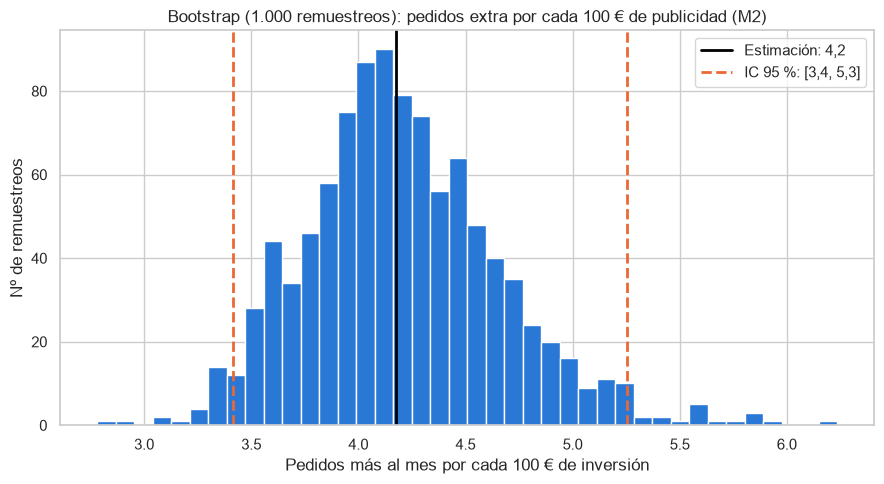

In [8]:
fig, ax = plt.subplots()
ax.hist(coefs_m2 * 100, bins=40, color=AZUL, edgecolor="white")
ax.axvline(beta_m2 * 100, color="black", linewidth=2, label=f"Estimación: {num(beta_m2 * 100, 1)}")
ax.axvline(ic_bajo * 100, color=NARANJA, linestyle="--", linewidth=2,
           label=f"IC 95 %: [{num(ic_bajo * 100, 1)}, {num(ic_alto * 100, 1)}]")
ax.axvline(ic_alto * 100, color=NARANJA, linestyle="--", linewidth=2)
ax.set_title("Bootstrap (1.000 remuestreos): pedidos extra por cada 100 € de publicidad (M2)")
ax.set_xlabel("Pedidos más al mes por cada 100 € de inversión")
ax.set_ylabel("Nº de remuestreos")
ax.legend()
fig.tight_layout()
guardar(fig, "bootstrap")
plt.show()

**Qué significa:** la mejor estimación es 4,2 pedidos más por cada 100 €. Pero, con solo 24 meses, el valor razonable está **entre 3,4 y 5,3** (intervalo del 95 %). En los 1.000 remuestreos el efecto es positivo (0 de 1000 con coeficiente ≤ 0): estamos seguros de que la publicidad ayuda, aunque no del número exacto.

## 5. Diagnóstico de M2

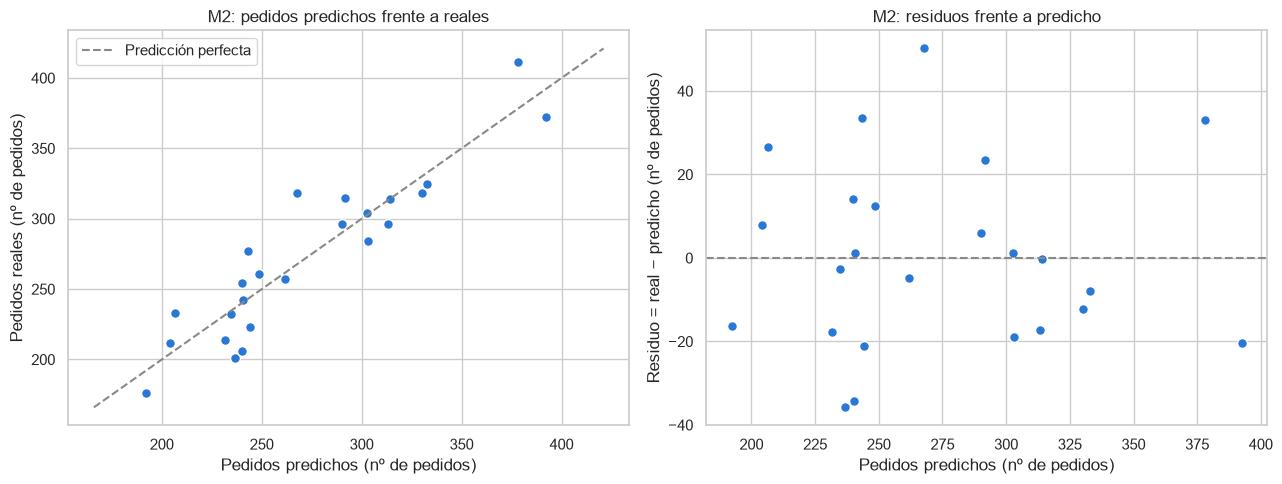

In [9]:
m2 = resultados["M2"]["modelo"]
mensual["pred_m2"] = m2.predict(mensual[MODELOS["M2"]])
mensual["residuo_m2"] = mensual["n_pedidos"] - mensual["pred_m2"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Predicho frente a real: si el modelo fuera perfecto, todos los puntos estarían en la diagonal
ax1.scatter(mensual["pred_m2"], mensual["n_pedidos"], color=AZUL, s=50, edgecolor="white")
limites = [mensual[["pred_m2", "n_pedidos"]].min().min() - 10, mensual[["pred_m2", "n_pedidos"]].max().max() + 10]
ax1.plot(limites, limites, color=GRIS, linestyle="--", label="Predicción perfecta")
ax1.set_title("M2: pedidos predichos frente a reales")
ax1.set_xlabel("Pedidos predichos (nº de pedidos)")
ax1.set_ylabel("Pedidos reales (nº de pedidos)")
ax1.legend()

# Residuos frente a predicho: no debería verse ningún patrón (nube alrededor de 0)
ax2.scatter(mensual["pred_m2"], mensual["residuo_m2"], color=AZUL, s=50, edgecolor="white")
ax2.axhline(0, color=GRIS, linestyle="--")
ax2.set_title("M2: residuos frente a predicho")
ax2.set_xlabel("Pedidos predichos (nº de pedidos)")
ax2.set_ylabel("Residuo = real − predicho (nº de pedidos)")

fig.tight_layout()
guardar(fig, "diagnostico")
plt.show()

**Lectura:** en el gráfico de la izquierda, los puntos siguen la diagonal: M2 predice bien el orden de magnitud de cada mes. En el de la derecha, los residuos forman una nube sin forma alrededor de 0 (desviación típica de 22,1 pedidos). No hay curva ni embudo, así que una recta es razonable para estos datos.

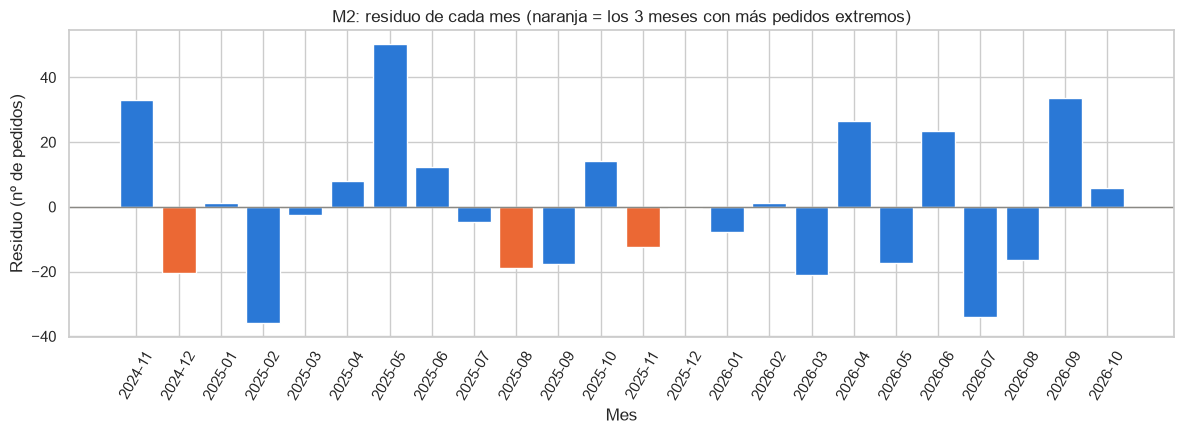

Desviación típica de los residuos: 22,1 pedidos
Correlación residuo – nº de pedidos extremos: -0.04


,mes,n_pedidos,pred_m2,residuo_m2,n_pedidos_extremos
1,2024-12,372,392.4,-20.4,14
9,2025-08,284,302.9,-18.9,10
12,2025-11,318,330.3,-12.3,11


In [10]:
# Residuos por mes, marcando los meses con más pedidos extremos
top_extremos = mensual.nlargest(3, "n_pedidos_extremos")["mes"]
colores = [NARANJA if mes in set(top_extremos) else AZUL for mes in mensual["mes"]]

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.bar(mensual["mes"], mensual["residuo_m2"], color=colores)
ax.axhline(0, color=GRIS, linewidth=1)
ax.set_title("M2: residuo de cada mes (naranja = los 3 meses con más pedidos extremos)")
ax.set_xlabel("Mes")
ax.set_ylabel("Residuo (nº de pedidos)")
ax.tick_params(axis="x", rotation=60)
fig.tight_layout()
plt.show()

desv = mensual["residuo_m2"].std()
print(f"Desviación típica de los residuos: {num(desv, 1)} pedidos")
print(f"Correlación residuo – nº de pedidos extremos: {mensual['residuo_m2'].corr(mensual['n_pedidos_extremos']):.2f}")
mensual.loc[mensual["mes"].isin(top_extremos), ["mes", "n_pedidos", "pred_m2", "residuo_m2", "n_pedidos_extremos"]].round(1)

**¿Destacan los meses con pedidos extremos?** No. Los 3 meses con más pedidos extremos (2024-12, 2025-08 y 2025-11) tienen residuos de -20,4, -18,9 y -12,3 pedidos, dentro de lo normal (desviación típica de 22,1), y la correlación entre residuo y nº de pedidos extremos es -0,04. Tiene sentido: un pedido enorme cuenta como **un** pedido, así que casi no mueve `n_pedidos`. Donde sí pesa es en los **euros** (sección 6). Por eso es más robusto modelar pedidos que ingresos.

## 6. Ingresos y el efecto de los pedidos extremos

Mismo M2 (`inversion_total` + `temporada_alta`), pero prediciendo euros en lugar de pedidos:
con todos los pedidos (`ingresos`) y sin los pedidos extremos (`ingresos_sin_extremos`).

In [11]:
res_ingresos = evaluar(MODELOS["M2"], "ingresos")
res_sin_ext = evaluar(MODELOS["M2"], "ingresos_sin_extremos")
mostrar("M2 · ingresos", res_ingresos, unidad="€")
mostrar("M2 · ingresos sin extremos", res_sin_ext, unidad="€")

comparacion = pd.DataFrame({
    "objetivo": ["ingresos", "ingresos_sin_extremos"],
    "€ por € de inversión": [r["modelo"].coef_[0] for r in (res_ingresos, res_sin_ext)],
    "temporada_alta (€)": [r["modelo"].coef_[1] for r in (res_ingresos, res_sin_ext)],
    "constante (€)": [r["modelo"].intercept_ for r in (res_ingresos, res_sin_ext)],
    "R² train": [r["r2_train"] for r in (res_ingresos, res_sin_ext)],
    "R² LOO": [r["loo"]["R2"] for r in (res_ingresos, res_sin_ext)],
    "MAE LOO (€)": [r["loo"]["MAE"] for r in (res_ingresos, res_sin_ext)],
})
cambio = 1 - res_sin_ext["modelo"].coef_[0] / res_ingresos["modelo"].coef_[0]
print(f"Quitar los pedidos extremos cambia la pendiente un {num(100 * cambio, 1)} %")
print(f"MAE LOO: {euros(res_ingresos['loo']['MAE'])} con extremos → {euros(res_sin_ext['loo']['MAE'])} sin extremos")
comparacion.round(3)

=== M2 · ingresos: ingresos ~ inversion_total + temporada_alta ===
Constante (β₀): 11.722,1 €
  inversion_total: 6.6967 → cada 100 € más → 669,7 € más al mes
  temporada_alta: 9.161,3 → noviembre y diciembre suman 9.161,3 € al mes
R² entrenamiento: 0.755
Temporal (6 últimos meses): MAE 5.072,7 | RMSE 7.028,5 | R² 0.534
Leave-One-Out (24 meses):   MAE 4.104,2 | RMSE 5.457,6 | R² 0.654

=== M2 · ingresos sin extremos: ingresos_sin_extremos ~ inversion_total + temporada_alta ===
Constante (β₀): 11.655,2 €
  inversion_total: 4.9141 → cada 100 € más → 491,4 € más al mes
  temporada_alta: 6.801,5 → noviembre y diciembre suman 6.801,5 € al mes
R² entrenamiento: 0.834
Temporal (6 últimos meses): MAE 2.825,0 | RMSE 3.429,5 | R² 0.691
Leave-One-Out (24 meses):   MAE 2.680,1 | RMSE 3.138,3 | R² 0.767

Quitar los pedidos extremos cambia la pendiente un 26,6 %
MAE LOO: 4.104 € con extremos → 2.680 € sin extremos


,objetivo,€ por € de inversión,temporada_alta (€),constante (€),R² train,R² LOO,MAE LOO (€)
0,ingresos,6.697,9161.298,11722.107,0.755,0.654,4104.156
1,ingresos_sin_extremos,4.914,6801.476,11655.226,0.834,0.767,2680.137


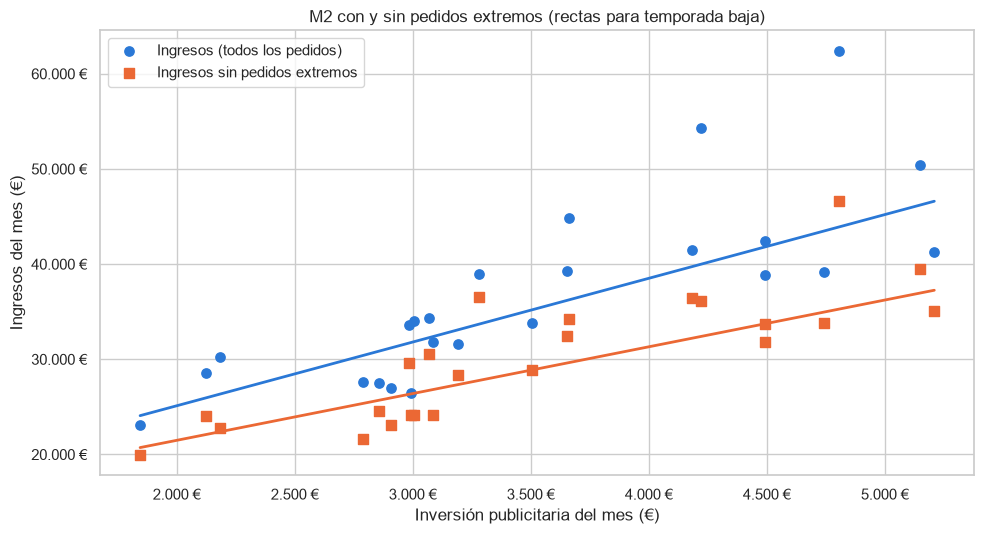

In [12]:
# Las dos rectas para un mes de temporada baja (temporada_alta = 0)
rango = np.linspace(mensual["inversion_total"].min(), mensual["inversion_total"].max(), 50)
X_recta = pd.DataFrame({"inversion_total": rango, "temporada_alta": 0})

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.scatter(mensual["inversion_total"], mensual["ingresos"], color=AZUL, s=45, label="Ingresos (todos los pedidos)")
ax.scatter(mensual["inversion_total"], mensual["ingresos_sin_extremos"], color=NARANJA, s=45, marker="s",
           label="Ingresos sin pedidos extremos")
ax.plot(rango, res_ingresos["modelo"].predict(X_recta), color=AZUL, linewidth=2)
ax.plot(rango, res_sin_ext["modelo"].predict(X_recta), color=NARANJA, linewidth=2)
ax.set_title("M2 con y sin pedidos extremos (rectas para temporada baja)")
ax.set_xlabel("Inversión publicitaria del mes (€)")
ax.set_ylabel("Ingresos del mes (€)")
ax.xaxis.set_major_formatter(FORMATO_EUROS)
ax.yaxis.set_major_formatter(FORMATO_EUROS)
ax.legend(loc="upper left")
fig.tight_layout()
guardar(fig, "extremos")
plt.show()

**Cuánto mueven la recta:** con todos los pedidos, cada 100 € de publicidad traen 669,7 € de ingresos; sin los pedidos extremos, 491,4 €. **La pendiente cambia un 26,6 %** por pedidos que son el 2,5 % del total. Sin ellos, el modelo además predice mucho mejor: el MAE LOO baja de 4.104 € a 2.680 € y el R² LOO sube de 0,654 a 0,767. Los pedidos enormes son ruido que la publicidad no explica: atribuirlos a la inversión inflaría su rentabilidad.

**Pero ojo:** Q3 + 3·IQR quita 161 pedidos que suman el 18,3 % de los ingresos, y muchos son pedidos Premium normales que la publicidad sí trae. Quitarlos también puede **infravalorar** la pendiente. El apartado 6.1 lo comprueba.

### 6.1 ¿Es razonable el umbral? Dos alternativas

Q3 + 3·IQR (531,12 €) se queda como **referencia**, y se compara con dos formas distintas de tratar los pedidos enormes:

- **a) Umbral más estricto: percentil 99,5** del importe por pedido. Solo se quita el 0,5 % de pedidos más grandes.
  Se calcula con `tabla_mensual(criterio="p995")`, la misma consulta SQL con otro umbral.
- **b) Sin excluir nada: regresión de Huber** sobre los ingresos con **todos** los pedidos. En lugar de quitar datos,
  Huber pondera menos los meses con residuos muy grandes: para errores pequeños se comporta como mínimos
  cuadrados (error²) y para errores grandes, como el error absoluto, así que un mes raro no arrastra la recta.

**Por qué estandarizar en Huber:** `HuberRegressor` decide qué es un error "grande" comparándolo con una escala
que estima a la vez que los coeficientes, y además lleva una pequeña penalización (`alpha`) sobre los coeficientes.
Con ingresos de decenas de miles de € e inversión de miles, esa penalización y la optimización dependen de las
unidades. Se estandarizan X e y (media 0, desviación 1), se ajusta y se **devuelven los coeficientes a euros**:

- pendiente en € = pendiente estandarizada × (desv. de y / desv. de x)
- constante en € = media de y + desv. de y × constante estandarizada − Σ (pendiente en € × media de x)

In [13]:
class HuberEscalado(BaseEstimator, RegressorMixin):
    """HuberRegressor con X e y estandarizadas y coeficientes devueltos a la escala original.

    Tras fit(): coef_ e intercept_ en las unidades de los datos (€ por €, €) y
    pesos_reducidos_ = True en las filas que Huber trata como atípicas.
    """

    def __init__(self, epsilon: float = 1.35):
        self.epsilon = epsilon

    def fit(self, X, y):
        X, y = np.asarray(X, dtype=float), np.asarray(y, dtype=float)
        self.media_x_, self.desv_x_ = X.mean(axis=0), X.std(axis=0)
        # En un remuestreo del bootstrap puede no salir ningún mes de temporada alta:
        # la columna es constante (desviación 0) y se deja sin escalar para no dividir entre 0
        self.desv_x_[self.desv_x_ == 0] = 1.0
        self.media_y_, self.desv_y_ = y.mean(), y.std()
        huber = HuberRegressor(epsilon=self.epsilon, max_iter=1000).fit(
            (X - self.media_x_) / self.desv_x_, (y - self.media_y_) / self.desv_y_)
        # Vuelta a la escala original
        self.coef_ = huber.coef_ * self.desv_y_ / self.desv_x_
        self.intercept_ = self.media_y_ + self.desv_y_ * huber.intercept_ - np.sum(self.coef_ * self.media_x_)
        self.pesos_reducidos_ = huber.outliers_
        return self

    def predict(self, X):
        return np.asarray(X, dtype=float) @ self.coef_ + self.intercept_


# a) Percentil 99,5: misma tabla con otro umbral; se añaden sus columnas a `mensual`
mensual_p995 = tabla_mensual(criterio="p995")
assert (mensual_p995["mes"] == mensual["mes"]).all()
umbral_p995 = mensual_p995.attrs["umbral_extremos"]
mensual["ingresos_sin_p995"] = mensual_p995["ingresos_sin_extremos"]
mensual["margen_sin_p995"] = mensual_p995["margen_sin_extremos"]
mensual["n_extremos_p995"] = mensual_p995["n_pedidos_extremos"]
print(f"Umbral P99,5 = {euros(umbral_p995['umbral'], 2)}: {umbral_p995['n_extremos']} pedidos "
      f"({num(100 * umbral_p995['n_extremos'] / umbral_p995['n_pedidos'], 1)} %), "
      f"{num(umbral_p995['pct_ingresos_extremos'], 1)} % de los ingresos\n")

res_p995 = evaluar(MODELOS["M2"], "ingresos_sin_p995")
mostrar("M2 · ingresos sin extremos (P99,5)", res_p995, unidad="€")

# b) Huber con todos los pedidos
res_huber = evaluar(MODELOS["M2"], "ingresos", estimador=HuberEscalado())
mostrar("M2 · ingresos con Huber (sin excluir nada)", res_huber, unidad="€")
meses_huber = mensual.loc[res_huber["modelo"].pesos_reducidos_, "mes"].tolist()
print(f"Meses a los que Huber reduce el peso ({len(meses_huber)} de {len(mensual)}): {', '.join(meses_huber)}")

# Comprobación de la vuelta a euros: el modelo estandarizado, deshaciendo la escala a mano,
# predice lo mismo que la recta con los coeficientes en euros
h = res_huber["modelo"]
X_m2 = mensual[MODELOS["M2"]].to_numpy(dtype=float)
huber_std = HuberRegressor(epsilon=h.epsilon, max_iter=1000).fit(
    (X_m2 - h.media_x_) / h.desv_x_, (mensual["ingresos"] - h.media_y_) / h.desv_y_)
pred_std = h.media_y_ + h.desv_y_ * huber_std.predict((X_m2 - h.media_x_) / h.desv_x_)
assert np.allclose(pred_std, h.predict(X_m2))
print("✔ Los coeficientes en euros reproducen el modelo estandarizado")

Umbral P99,5 = 1.064,63 €: 33 pedidos (0,5 %), 8,0 % de los ingresos

=== M2 · ingresos sin extremos (P99,5): ingresos_sin_p995 ~ inversion_total + temporada_alta ===
Constante (β₀): 12.649,8 €
  inversion_total: 5.6655 → cada 100 € más → 566,5 € más al mes
  temporada_alta: 7.800,6 → noviembre y diciembre suman 7.800,6 € al mes
R² entrenamiento: 0.882
Temporal (6 últimos meses): MAE 2.956,3 | RMSE 3.212,5 | R² 0.772
Leave-One-Out (24 meses):   MAE 2.368,1 | RMSE 2.796,3 | R² 0.852

=== M2 · ingresos con Huber (sin excluir nada): ingresos ~ inversion_total + temporada_alta ===
Constante (β₀): 14.195,8 €
  inversion_total: 5.8130 → cada 100 € más → 581,3 € más al mes
  temporada_alta: 8.285,8 → noviembre y diciembre suman 8.285,8 € al mes
R² entrenamiento: 0.736
Temporal (6 últimos meses): MAE 5.242,6 | RMSE 7.242,7 | R² 0.505
Leave-One-Out (24 meses):   MAE 3.852,1 | RMSE 5.198,8 | R² 0.686

Meses a los que Huber reduce el peso (5 de 24): 2024-11, 2025-02, 2025-05, 2026-06, 2026-07
✔ L

In [14]:
# Tabla comparativa. Pendiente = € de ingresos por cada 100 € de publicidad; IC 95 % por bootstrap (1.000 remuestreos)
total_ingresos = mensual["ingresos"].sum()
alternativas = [
    # (nombre, resultado, objetivo, estimador, pedidos excluidos, ingresos excluidos)
    ("MCO, todos los pedidos", res_ingresos, "ingresos", None, 0, 0.0),
    ("Q3 + 3·IQR (referencia)", res_sin_ext, "ingresos_sin_extremos", None,
     umbral["n_extremos"], total_ingresos - mensual["ingresos_sin_extremos"].sum()),
    ("a) Percentil 99,5", res_p995, "ingresos_sin_p995", None,
     umbral_p995["n_extremos"], total_ingresos - mensual["ingresos_sin_p995"].sum()),
    ("b) Huber, sin excluir", res_huber, "ingresos", HuberEscalado(), 0, 0.0),
]
filas = []
for nombre, res, objetivo, estimador, n_excluidos, ingresos_excluidos in alternativas:
    ic = np.percentile(bootstrap(MODELOS["M2"], objetivo, estimador=estimador), [2.5, 97.5])
    filas.append({
        "criterio": nombre,
        "€ por cada 100 €": 100 * res["modelo"].coef_[0],
        "IC 95 % bajo": 100 * ic[0],
        "IC 95 % alto": 100 * ic[1],
        "R² LOO": res["loo"]["R2"],
        "MAE LOO (€)": res["loo"]["MAE"],
        "pedidos excluidos": n_excluidos,
        "% ingresos excluidos": 100 * ingresos_excluidos / total_ingresos,
    })
tabla_alternativas = pd.DataFrame(filas).set_index("criterio")
tabla_alternativas.round(3)

,€ por cada 100 €,IC 95 % bajo,IC 95 % alto,R² LOO,MAE LOO (€),pedidos excluidos,% ingresos excluidos
criterio,,,,,,,
"MCO, todos los pedidos",669.670,486.148,989.525,0.654,4104.156,0,0.000
Q3 + 3·IQR (referencia),491.411,400.890,649.823,0.767,2680.137,161,18.287
"a) Percentil 99,5",566.547,465.328,713.710,0.852,2368.113,33,7.952
"b) Huber, sin excluir",581.302,414.207,988.159,0.686,3852.082,0,0.000


**Cómo leer la tabla:** R² y MAE de las filas que excluyen pedidos se miden contra **su propio** objetivo (ingresos
sin esos pedidos), que es más fácil de predecir cuanto más se quita. Por eso no basta con elegir el mejor R²: hay
que mirar también cuánto se excluye y si la pendiente coincide con la de otros métodos.

| Criterio | € por cada 100 € | IC 95 % | R² LOO | MAE LOO | Pedidos excluidos | % ingresos excluidos |
|---|---:|---:|---:|---:|---:|---:|
| MCO, todos los pedidos | 669,7 € | 486 – 990 € | 0,654 | 4.104 € | 0 | 0 % |
| Q3 + 3·IQR (referencia) | 491,4 € | 401 – 650 € | 0,767 | 2.680 € | 161 | 18,3 % |
| **a) Percentil 99,5** | **566,5 €** | **465 – 714 €** | **0,852** | **2.368 €** | **33** | **8,0 %** |
| b) Huber, sin excluir | 581,3 € | 414 – 988 € | 0,686 | 3.852 € | 0 | 0 % |

**Cifra elegida: 566,5 € de ingresos por cada 100 € de publicidad (percentil 99,5).** Motivos:

1. **Dos métodos independientes coinciden.** P99,5 (quita 33 pedidos) y Huber (no quita nada) dan 566,5 € y 581,3 €:
   una diferencia del 2,6 %. Las dos versiones anteriores quedan a los lados: con todos los pedidos (669,7 €), dos
   pedidos de más de 10.000 € inflan la recta; con Q3 + 3·IQR (491,4 €), se quitan también pedidos Premium normales
   que la publicidad sí trae, y la recta se queda corta.
2. **Excluye poco:** 33 pedidos (0,5 %) y el 8,0 % de los ingresos, frente a 161 pedidos y el 18,3 %.
3. **Mejor en Leave-One-Out** de las cuatro (R² LOO 0,852, MAE LOO 2.368 €), con la precaución de arriba. En la
   validación temporal queda cerca de Q3 + 3·IQR (MAE de 2.956 € frente a 2.825 €).
4. **Frente a Huber:** Huber no quita pedidos, sino que pondera menos **meses enteros** (aquí, 5 de 24), y su
   intervalo es mucho más ancho (414 – 988 €). P99,5 actúa pedido a pedido, se explica en una frase y sirve igual para el margen
   (sección 7). Huber queda como comprobación de robustez.

Q3 + 3·IQR se mantiene como referencia conservadora.

## 7. Rentabilidad: ¿cuánto margen bruto deja cada euro de publicidad?

Se modela **directamente `margen_bruto`** (ingresos − coste de los productos vendidos) con M2, en
lugar de multiplicar los ingresos por un margen medio. Motivo: el margen cambia de un mes a otro
según qué productos se venden (Electrónica Premium no deja el mismo margen que un libro), y
`tabla_mensual()` ya calcula el coste real de cada mes. Así no suponemos un margen fijo.

In [15]:
res_margen = evaluar(MODELOS["M2"], "margen_bruto")
mostrar("M2 · margen bruto", res_margen, unidad="€")

coefs_margen = bootstrap(MODELOS["M2"], "margen_bruto")
beta_margen = res_margen["modelo"].coef_[0]
mg_bajo, mg_alto = np.percentile(coefs_margen, [2.5, 97.5])
print(f"Cada € de publicidad genera {num(beta_margen, 2)} € de margen bruto "
      f"(IC 95 %: {num(mg_bajo, 2)} – {num(mg_alto, 2)} €)")
print(f"Beneficio neto por € invertido (margen − el propio €): {num(beta_margen - 1, 2)} € "
      f"(IC 95 %: {num(mg_bajo - 1, 2)} – {num(mg_alto - 1, 2)} €)")
print(f"Remuestreos en los que el margen por € no cubre el € invertido (< 1): {(coefs_margen < 1).sum()} de {len(coefs_margen)}")
print(f"Rango de inversión observado: {euros(mensual['inversion_total'].min())} – {euros(mensual['inversion_total'].max())} al mes")

=== M2 · margen bruto: margen_bruto ~ inversion_total + temporada_alta ===
Constante (β₀): 4.264,3 €
  inversion_total: 2.8238 → cada 100 € más → 282,4 € más al mes
  temporada_alta: 3.817,7 → noviembre y diciembre suman 3.817,7 € al mes
R² entrenamiento: 0.734
Temporal (6 últimos meses): MAE 1.977,3 | RMSE 2.910,5 | R² 0.526
Leave-One-Out (24 meses):   MAE 1.801,0 | RMSE 2.461,5 | R² 0.612



Cada € de publicidad genera 2,82 € de margen bruto (IC 95 %: 2,00 – 4,24 €)
Beneficio neto por € invertido (margen − el propio €): 1,82 € (IC 95 %: 1,00 – 3,24 €)
Remuestreos en los que el margen por € no cubre el € invertido (< 1): 0 de 1000
Rango de inversión observado: 1.845 € – 5.209 € al mes


In [16]:
# Estimación conservadora: el mismo modelo sin los pedidos extremos (la sección 6 muestra
# que inflan la pendiente de los ingresos, así que también pueden inflar la del margen)
res_margen_sin = evaluar(MODELOS["M2"], "margen_sin_extremos")
mostrar("M2 · margen sin extremos", res_margen_sin, unidad="€")

coefs_margen_sin = bootstrap(MODELOS["M2"], "margen_sin_extremos")
beta_margen_sin = res_margen_sin["modelo"].coef_[0]
ms_bajo, ms_alto = np.percentile(coefs_margen_sin, [2.5, 97.5])
print(f"Sin extremos: cada € de publicidad genera {num(beta_margen_sin, 2)} € de margen bruto "
      f"(IC 95 %: {num(ms_bajo, 2)} – {num(ms_alto, 2)} €)")
print(f"Beneficio neto por € invertido: {num(beta_margen_sin - 1, 2)} € (IC 95 %: {num(ms_bajo - 1, 2)} – {num(ms_alto - 1, 2)} €)")
print(f"Remuestreos con margen por € < 1: {(coefs_margen_sin < 1).sum()} de {len(coefs_margen_sin)}")

=== M2 · margen sin extremos: margen_sin_extremos ~ inversion_total + temporada_alta ===
Constante (β₀): 4.500,9 €
  inversion_total: 2.0109 → cada 100 € más → 201,1 € más al mes
  temporada_alta: 2.625,8 → noviembre y diciembre suman 2.625,8 € al mes
R² entrenamiento: 0.823
Temporal (6 últimos meses): MAE 1.219,2 | RMSE 1.493,3 | R² 0.651
Leave-One-Out (24 meses):   MAE 1.085,5 | RMSE 1.293,8 | R² 0.758



Sin extremos: cada € de publicidad genera 2,01 € de margen bruto (IC 95 %: 1,61 – 2,70 €)
Beneficio neto por € invertido: 1,01 € (IC 95 %: 0,61 – 1,70 €)
Remuestreos con margen por € < 1: 0 de 1000


In [17]:
# Estimación elegida: sin los pedidos por encima del percentil 99,5 (criterio de la sección 6.1)
res_margen_p995 = evaluar(MODELOS["M2"], "margen_sin_p995")
mostrar("M2 · margen sin extremos (P99,5)", res_margen_p995, unidad="€")

coefs_margen_p995 = bootstrap(MODELOS["M2"], "margen_sin_p995")
beta_margen_p995 = res_margen_p995["modelo"].coef_[0]
mp_bajo, mp_alto = np.percentile(coefs_margen_p995, [2.5, 97.5])
margen_excluido = 1 - mensual["margen_sin_p995"].sum() / mensual["margen_bruto"].sum()
print(f"P99,5: cada € de publicidad genera {num(beta_margen_p995, 2)} € de margen bruto "
      f"(IC 95 %: {num(mp_bajo, 2)} – {num(mp_alto, 2)} €)")
print(f"Beneficio neto por € invertido: {num(beta_margen_p995 - 1, 2)} € (IC 95 %: {num(mp_bajo - 1, 2)} – {num(mp_alto - 1, 2)} €)")
print(f"Remuestreos con margen por € < 1: {(coefs_margen_p995 < 1).sum()} de {len(coefs_margen_p995)}")
print(f"Margen excluido: {num(100 * margen_excluido, 1)} % "
      f"(con Q3 + 3·IQR: {num(100 * (1 - mensual['margen_sin_extremos'].sum() / mensual['margen_bruto'].sum()), 1)} %)")

pd.DataFrame({
    "estimación": ["Todos los pedidos", "Sin extremos Q3 + 3·IQR (referencia)", "Sin extremos P99,5 (elegida)"],
    "margen por €": [beta_margen, beta_margen_sin, beta_margen_p995],
    "IC 95 % bajo": [mg_bajo, ms_bajo, mp_bajo],
    "IC 95 % alto": [mg_alto, ms_alto, mp_alto],
    "R² LOO": [r["loo"]["R2"] for r in (res_margen, res_margen_sin, res_margen_p995)],
    "MAE LOO (€)": [r["loo"]["MAE"] for r in (res_margen, res_margen_sin, res_margen_p995)],
}).set_index("estimación").round(3)

=== M2 · margen sin extremos (P99,5): margen_sin_p995 ~ inversion_total + temporada_alta ===
Constante (β₀): 4.911,9 €
  inversion_total: 2.3334 → cada 100 € más → 233,3 € más al mes
  temporada_alta: 3.126,3 → noviembre y diciembre suman 3.126,3 € al mes
R² entrenamiento: 0.867
Temporal (6 últimos meses): MAE 1.209,5 | RMSE 1.399,7 | R² 0.744
Leave-One-Out (24 meses):   MAE 1.024,1 | RMSE 1.234,6 | R² 0.830



P99,5: cada € de publicidad genera 2,33 € de margen bruto (IC 95 %: 1,87 – 3,01 €)
Beneficio neto por € invertido: 1,33 € (IC 95 %: 0,87 – 2,01 €)
Remuestreos con margen por € < 1: 0 de 1000
Margen excluido: 8,0 % (con Q3 + 3·IQR: 19,0 %)


,margen por €,IC 95 % bajo,IC 95 % alto,R² LOO,MAE LOO (€)
estimación,,,,,
Todos los pedidos,2.824,2.000,4.238,0.612,1800.961
Sin extremos Q3 + 3·IQR (referencia),2.011,1.606,2.704,0.758,1085.523
"Sin extremos P99,5 (elegida)",2.333,1.872,3.006,0.830,1024.125


**¿Compensa invertir más?** Sí, dentro del rango observado.

| Estimación | Margen bruto por € | IC 95 % | R² LOO |
|---|---:|---:|---:|
| Con todos los pedidos | 2,82 € | 2,00 – 4,24 € | 0,612 |
| Sin extremos Q3 + 3·IQR (referencia, la más conservadora) | 2,01 € | 1,61 – 2,70 € | 0,758 |
| **Sin extremos P99,5 (elegida, criterio de la sección 6.1)** | **2,33 €** | **1,87 – 3,01 €** | **0,830** |

- **Cifra elegida:** cada € de publicidad deja **2,33 € de margen bruto**, unos 1,33 € netos por cada € invertido. Quita solo el 8,0 % del margen (frente al 19,0 % de Q3 + 3·IQR) y es la que mejor predice en Leave-One-Out (MAE de 1.024 €).
- **La conclusión no depende del criterio:** incluso con la versión más conservadora (Q3 + 3·IQR), en ningún remuestreo el margen por € baja de 1 € (0 de 1000).

**Precauciones:**

- Solo vale entre 1.845 € y 5.209 € al mes. Fuera de ese rango no sabemos si cada € extra rinde igual: lo normal es que la publicidad tenga rendimientos decrecientes, y una recta no los puede ver.
- El margen bruto no descuenta envíos, devoluciones ni costes fijos.

## 8. Resumen de modelos y elección del modelo final

In [18]:
todos = {"M1 · n_pedidos": resultados["M1"], "M2 · n_pedidos": resultados["M2"], "M3 · n_pedidos": resultados["M3"],
         "M2 · ingresos": res_ingresos, "M2 · ingresos sin extremos": res_sin_ext, "M2 · ingresos sin extremos P99,5": res_p995,
         "M2 · ingresos Huber": res_huber, "M2 · margen bruto": res_margen,
         "M2 · margen sin extremos": res_margen_sin, "M2 · margen sin extremos P99,5": res_margen_p995}
resumen = pd.DataFrame([{
    "modelo": nombre,
    "variables": " + ".join(r["variables"]),
    "R² train": r["r2_train"],
    "MAE temporal": r["temporal"]["MAE"],
    "MAE LOO": r["loo"]["MAE"],
    "R² LOO": r["loo"]["R2"],
} for nombre, r in todos.items()])
resumen.round(3)

,modelo,variables,R² train,MAE temporal,MAE LOO,R² LOO
0,M1 · n_pedidos,inversion_total,0.699,23.587,27.897,0.637
1,M2 · n_pedidos,inversion_total + temporada_alta,0.850,22.517,19.908,0.808
2,M3 · n_pedidos,inversion_google_ads + inversion_meta_ads + in...,0.855,21.952,21.971,0.766
3,M2 · ingresos,inversion_total + temporada_alta,0.755,5072.689,4104.156,0.654
4,M2 · ingresos sin extremos,inversion_total + temporada_alta,0.834,2824.991,2680.137,0.767
5,"M2 · ingresos sin extremos P99,5",inversion_total + temporada_alta,0.882,2956.316,2368.113,0.852
6,M2 · ingresos Huber,inversion_total + temporada_alta,0.736,5242.554,3852.082,0.686
7,M2 · margen bruto,inversion_total + temporada_alta,0.734,1977.333,1800.961,0.612
8,M2 · margen sin extremos,inversion_total + temporada_alta,0.823,1219.213,1085.523,0.758
9,"M2 · margen sin extremos P99,5",inversion_total + temporada_alta,0.867,1209.512,1024.125,0.830


**Modelo final: M2 para `n_pedidos`** (`inversion_total` + `temporada_alta`). Motivos:

- **Mejor fuera de muestra:** tiene el mejor MAE LOO (19,9 pedidos) y el mejor R² LOO (0,808) de los modelos de pedidos.
- **Temporal:** en la validación temporal M3 queda casi igual (22,0 frente a 22,5 pedidos), pero con más variables y coeficientes inestables.
- **Fácil de explicar:** se resume en una frase de negocio.
- **Robusto:** predecir pedidos no depende de unos pocos pedidos enormes, como sí pasa con los ingresos (sección 6).

Para hablar de **euros**, el modelo recomendado es M2 · margen sin extremos **P99,5** (sección 6.1); el de Q3 + 3·IQR queda como referencia conservadora.

In [19]:
# Modelo final: M2 para n_pedidos, entrenado con los 24 meses.
# Se guarda "datos_hasta" (último mes de los datos) y no la fecha de hoy: así, con los mismos
# datos, el archivo es idéntico byte a byte entre ejecuciones.
MODELO_FINAL = "M2"
paquete = {
    "modelo": resultados[MODELO_FINAL]["modelo"],
    "variables": MODELOS[MODELO_FINAL],
    "objetivo": "n_pedidos",
    "datos_hasta": mensual["mes"].iloc[-1],
    "meses_entrenamiento": f"{mensual['mes'].iloc[0]} a {mensual['mes'].iloc[-1]}",
    "rango_inversion": (float(mensual["inversion_total"].min()), float(mensual["inversion_total"].max())),
}
ruta_modelo = CARPETA_MODELOS / "regresion_pedidos.joblib"
joblib.dump(paquete, ruta_modelo)
print("Modelo guardado en", ruta_modelo.relative_to(RAIZ))
print("Claves:", list(paquete), "| datos_hasta =", paquete["datos_hasta"])

# Comprobación: se carga y predice
cargado = joblib.load(ruta_modelo)
ejemplo = pd.DataFrame({"inversion_total": [3000, 4000], "temporada_alta": [0, 0]})[cargado["variables"]]
for inversion, pedidos in zip(ejemplo["inversion_total"], cargado["modelo"].predict(ejemplo)):
    print(f"Temporada baja con {euros(inversion)} de publicidad → {num(pedidos, 1)} pedidos previstos")

Modelo guardado en models\regresion_pedidos.joblib
Claves: ['modelo', 'variables', 'objetivo', 'datos_hasta', 'meses_entrenamiento', 'rango_inversion'] | datos_hasta = 2026-10
Temporada baja con 3.000 € de publicidad → 240,6 pedidos previstos
Temporada baja con 4.000 € de publicidad → 282,3 pedidos previstos


## 9. ✅ Validación del método (solo posible porque los datos son simulados)

> **Esta sección no se podría hacer en una empresa real:** allí nadie conoce el efecto verdadero
> de la publicidad; es justo lo que se intenta estimar. Aquí lo sabemos porque nosotros generamos
> los datos, y sirve para comprobar si el método recupera la verdad.

El generador usa `Pedidos_por_euro = 0.05` (5 pedidos por cada 100 €). Pero ese valor se aplica a
**todos** los pedidos generados, y nuestro modelo cuenta solo los **completados que sobreviven a la
limpieza**. Hay que ajustar el valor esperado por esas dos proporciones.

In [20]:
from generar_datos import Pedidos_por_euro  # constante del generador (no es un archivo _verdad_)
from bd import leer_sql

# Proporción de pedidos que sobreviven a la limpieza: pedidos en la BD / pedidos distintos en el CSV en bruto
n_bruto = pd.read_csv(RAIZ / "data" / "raw" / "pedidos.csv")["id_pedido"].nunique()
estados = leer_sql("SELECT COUNT(*) AS total, SUM(estado = 'completado') AS completados FROM pedidos")
n_bd, n_completados = int(estados["total"][0]), int(estados["completados"][0])
retencion = n_bd / n_bruto
prop_completados = n_completados / n_bd
esperado = Pedidos_por_euro * retencion * prop_completados

print(f"Pedidos_por_euro del generador: {Pedidos_por_euro}")
print(f"Sobreviven a la limpieza: {n_bd} de {n_bruto} ({num(100 * retencion, 1)} %)")
print(f"Completados: {n_completados} de {n_bd} ({num(100 * prop_completados, 1)} %)")
print(f"Valor esperado para n_pedidos completados: {Pedidos_por_euro} × {retencion:.3f} × {prop_completados:.3f} = {esperado:.4f}")
print(f"Estimado por M2: {beta_m2:.4f} | IC 95 % bootstrap: [{ic_bajo:.4f}, {ic_alto:.4f}]")
print("¿El valor esperado cae dentro del intervalo?", "Sí" if ic_bajo <= esperado <= ic_alto else "No")
print("¿Y el 0,05 sin ajustar?", "Sí" if ic_bajo <= Pedidos_por_euro <= ic_alto else "No")

Pedidos_por_euro del generador: 0.05
Sobreviven a la limpieza: 7297 de 7895 (92,4 %)
Completados: 6541 de 7297 (89,6 %)
Valor esperado para n_pedidos completados: 0.05 × 0.924 × 0.896 = 0.0414
Estimado por M2: 0.0418 | IC 95 % bootstrap: [0.0341, 0.0525]
¿El valor esperado cae dentro del intervalo? Sí
¿Y el 0,05 sin ajustar? Sí


**Resultado:** el generador usa 0,05 pedidos por €. Ajustado a pedidos completados que sobreviven a la limpieza (92,4 % × 89,6 %), el valor esperado es 0,0414. M2 estima 0,0418: casi exacto, y dentro del intervalo del bootstrap [0,0341; 0,0525]. El método funciona, y M2 recupera el efecto real porque separa la temporada; M1 (0,0502) lo sobreestimaba. **En un caso real este valor no se conoce:** esta sección solo es posible porque los datos son simulados.

## 10. Conclusiones

1. **Respuesta a la pregunta de negocio:** cada 100 € más de publicidad traen **4,2 pedidos completados más al mes** (IC 95 %: 3,4 – 5,3), descontando la temporada alta, que por sí sola suma 62,1 pedidos al mes.
2. **En euros:** cada 100 € traen **566,5 € de ingresos** (IC 95 %: 465 – 714 €) sin los pedidos por encima del percentil 99,5. Huber, sin excluir ningún pedido, da casi lo mismo (581,3 €). Con todos los pedidos sale 669,7 € (inflado por dos pedidos de más de 10.000 €) y con Q3 + 3·IQR, 491,4 € (se queda corto porque quita también pedidos Premium normales).
3. **Rentabilidad:** cada € de publicidad deja **2,33 € de margen bruto** con el criterio P99,5 (IC 95 %: 1,87 – 3,01 €); 2,01 € en la referencia más conservadora (Q3 + 3·IQR). Compensa invertir más con cualquiera de los dos, pero solo podemos afirmarlo entre 1.845 € y 5.209 € al mes.
4. **Modelo final M2:** MAE LOO de 19,9 pedidos y R² LOO de 0,808. M3 (por canal) se sobreajusta: más R² de entrenamiento (0,855), pero peor fuera de muestra (MAE LOO 22,0).
5. **Pedidos extremos:** el criterio importa. Q3 + 3·IQR marca 161 pedidos (2,5 %) que son el 18,3 % de los ingresos y bajan la pendiente un 26,6 %; el percentil 99,5 marca 33 pedidos (0,5 %, 8,0 % de los ingresos). En `n_pedidos` apenas influyen (correlación con el residuo de -0,04).
6. **Validación del método:** el coeficiente estimado (0,0418) casi coincide con el efecto real del generador ajustado (0,0414) y cae dentro del intervalo del bootstrap.
7. **Limitaciones:** solo hay 24 meses, la inversión sube justo en temporada alta (por eso M1 exageraba) y una recta no puede ver rendimientos decrecientes. Correlación no es causalidad: un experimento (por ejemplo, variar la inversión a propósito unos meses) lo confirmaría.